# Planejamento de Manutenções no Metrô de São Paulo
## Análise exploratória oficial
**Grupo:** Júlia Gonzaga Heringer, Pedro Henrique Dornelas Pereira, Raphael Miranda da Silva e Danielle Carotta.  
**Curso:** Banco de Dados — Universidade Presbiteriana Mackenzie.  
**Disciplina:** Projeto Aplicado I.

Este notebook trata os quatro CSVs do repositório, verifica sua qualidade e apresenta demanda, oferta e comparação de fins de semana. A análise oferece evidências descritivas para o planejamento. Não determina horários de manutenção nem comprova impactos de intervenções.

**Como executar:** descompacte o projeto e abra este notebook. Use **Reiniciar kernel e executar todas as células**. No Colab, envie o ZIP completo do projeto quando solicitado pela célula de localização. O notebook utiliza os módulos da pasta `scripts/`, que acompanham esta entrega.

## 1 Preparação do ambiente
As dependências estão em `requirements.txt`. No ambiente local, instale com `python -m pip install -r requirements.txt`. No Colab, se houver erro de dependência, execute `%pip install -r CAMINHO_DO_PROJETO/requirements.txt` e reinicie a sessão. Não é necessário enviar os CSVs individualmente.

In [1]:
from pathlib import Path
import sys
import zipfile
import importlib
import pandas as pd
from IPython.display import display, Markdown, Image, SVG

# Funciona com o kernel iniciado na raiz ou na pasta notebooks.
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts/preparar_dados.py").exists() and (p / "dados").is_dir()), None)
if raiz is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Abra este notebook dentro da pasta descompactada do projeto.")
    print("Envie o ZIP completo do projeto corrigido.")
    enviados = files.upload()
    zips = [nome for nome in enviados if nome.lower().endswith(".zip")]
    if len(zips) != 1:
        raise ValueError("Envie exatamente um ZIP do projeto.")
    destino = Path.cwd() / "projeto_metro_colab"
    destino.mkdir(exist_ok=True)
    with zipfile.ZipFile(zips[0]) as arquivo:
        for item in arquivo.infolist():
            alvo = (destino / item.filename).resolve()
            if not alvo.is_relative_to(destino.resolve()):
                raise ValueError("Caminho inválido no ZIP.")
        arquivo.extractall(destino)
    candidatos = sorted({p.parent.parent for p in destino.rglob("preparar_dados.py")
                         if p.parent.name == "scripts" and (p.parent.parent / "dados").is_dir()})
    if len(candidatos) != 1:
        raise ValueError("Não foi possível identificar uma única raiz do projeto.")
    raiz = candidatos[0]
raiz = raiz.resolve()
sys.path.insert(0, str(raiz))
from scripts import preparar_dados, storytelling_eda, analise_fins_de_semana, estatisticas_eda
for modulo in [preparar_dados, storytelling_eda, analise_fins_de_semana, estatisticas_eda]:
    importlib.reload(modulo)
tratados = raiz / "dados_tratados"
resultados = raiz / "resultados"
print("Projeto:", raiz)


Projeto: /workspace/scratch/8d74b77efb98/output/Projeto_Aplicado_I_Corrigido


## 2 Fontes e variáveis
Os arquivos de origem estão em `dados/`, preservados sem alterações. As referências abaixo correspondem aos nomes e às notas presentes nos próprios CSVs; não foram acrescentados endereços de download não verificados.

| Arquivo | Período | Conteúdo |
|---|---|---|
| Entrada de Passageiros por Linha  - 2025_8.csv | 2025 | Totais mensais, médias por tipo de dia e máxima diária |
| Entrada de Passageiros por Estação - Diária - 2025_7.csv | 2025 | Entradas diárias por estação e linha |
| Oferta - 2026_4.csv | 2026 | Intervalo mínimo e velocidade comercial; sete meses com valores |
| Infraestrutura - 2024_11.csv | 2024 | Características físicas e operacionais |

**Unidades:** `entradas_mil`, `mdu_mil`, `msa_mil`, `mdo_mil` e `max_mil` estão em milhares de entradas. `MDU` significa média dos dias úteis; `MSA`, média dos sábados; `MDO`, média dos domingos; `MAX`, máxima diária. Entradas não equivalem necessariamente a pessoas únicas. As notas da fonte incluem transferências na contagem.

`ano` e `mes` identificam o período; `data` é a data completa; `linha` e `estacao` são categorias. `valor` na oferta precisa ser interpretado junto com `metrica`, em segundos ou km/h. `valor_fonte` preserva a representação original. A infraestrutura contém unidades heterogêneas e uma informação de frota compartilhada que não deve ser atribuída artificialmente a cada linha.

## 3 Tratamento dos dados
O código localiza os blocos pelos cabeçalhos, converte a notação brasileira, preserva marcadores ausentes e valida as chaves. Janeiro é extraído do arquivo, sem inclusão manual. Não há exclusão automática de outliers.

In [2]:
preparar_dados.main(["--dados", str(raiz / "dados"), "--saida", str(tratados)])
mensais = pd.read_csv(tratados / "demanda_mensal.csv")
diaria = pd.read_csv(tratados / "demanda_diaria_linha.csv", parse_dates=["data"])
estacoes = pd.read_csv(tratados / "demanda_diaria_estacao.csv", parse_dates=["data"],
                       keep_default_na=False, na_values={"entradas_mil": [""]})
oferta = pd.read_csv(tratados / "oferta_mensal.csv")
infraestrutura = pd.read_csv(tratados / "infraestrutura.csv", keep_default_na=False)
display(mensais.head(), diaria.head(), estacoes.head())

demanda_mensal: 60 registros
demanda_diaria_estacao: 24,090 registros
demanda_diaria_linha: 1,460 registros
oferta_mensal: 96 registros
infraestrutura: 55 registros


,ano,mes,linha,entradas_mil,mdu_mil,msa_mil,mdo_mil,max_mil
0,2025,1,Linha 1-Azul,18128.0,695.0,439.0,250.0,745.0
1,2025,1,Linha 15-Prata,1862.0,73.0,41.0,22.0,78.0
2,2025,1,Linha 2-Verde,11528.0,455.0,218.0,144.0,506.0
3,2025,1,Linha 3-Vermelha,19816.0,759.0,462.0,286.0,864.0
4,2025,1,Rede,51334.0,1981.0,1159.0,703.0,2143.0


,data,linha,entradas_mil
0,2025-01-01,Linha 1-Azul,173.7
1,2025-01-01,Linha 15-Prata,14.4
2,2025-01-01,Linha 2-Verde,81.2
3,2025-01-01,Linha 3-Vermelha,166.3
4,2025-01-02,Linha 1-Azul,482.9


,data,linha,estacao,entradas_mil,valor_fonte
0,2025-01-01,Linha 1-Azul,ANR,2.8,"2,8"
1,2025-01-01,Linha 1-Azul,ARV,1.9,"1,9"
2,2025-01-01,Linha 1-Azul,BTO,2.9,"2,9"
3,2025-01-01,Linha 1-Azul,CDU,1.5,"1,5"
4,2025-01-01,Linha 1-Azul,CON,4.3,"4,3"


## 4 Indicadores e verificações de consistência
A soma dos totais diários é comparada ao total mensal publicado. A tolerância considera o arredondamento dos totais mensais a mil entradas e dos diários a 0,1 mil. Diferenças dentro desse limite não demonstram exatidão além da precisão publicada.

In [3]:
storytelling_eda.main(["--dados", str(tratados), "--saida", str(resultados)])
conciliacao = pd.read_csv(resultados / "reconciliacao_mensal.csv")
display(conciliacao)
assert conciliacao["dentro_tolerancia"].all(), "Verifique as diferenças entre totais diários e mensais."

8 tabelas e 3 gráficos em /workspace/scratch/8d74b77efb98/output/Projeto_Aplicado_I_Corrigido/resultados
Reconciliação mensal: 48/48 comparações dentro da tolerância de arredondamento


,ano,mes,linha,entradas_mil,soma_diaria_mil,dias_com_valor,diferenca_mil,dentro_tolerancia
0,2025,1,Linha 1-Azul,18128.0,18128.1,31,0.1,True
1,2025,1,Linha 15-Prata,1862.0,1861.6,31,-0.4,True
2,2025,1,Linha 2-Verde,11528.0,11528.0,31,0.0,True
3,2025,1,Linha 3-Vermelha,19816.0,19816.4,31,0.4,True
4,2025,2,Linha 1-Azul,19001.0,19001.2,28,0.2,True
5,2025,2,Linha 15-Prata,1979.0,1979.1,28,0.1,True
6,2025,2,Linha 2-Verde,12511.0,12510.7,28,-0.3,True
7,2025,2,Linha 3-Vermelha,20708.0,20708.2,28,0.2,True
8,2025,3,Linha 1-Azul,20116.0,20116.5,31,0.5,True
9,2025,3,Linha 15-Prata,2055.0,2055.3,31,0.3,True


## 5 Qualidade e estatísticas descritivas
As medidas são calculadas nas tabelas tratadas. Variância e desvio padrão são **amostrais**, com `ddof=1`; a variância usa o quadrado da unidade da variável. A rede agregada não é adicionada às linhas para calcular uma demanda total duplicada.

Os limites de outliers são Q1 − 1,5 × IQR e Q3 + 1,5 × IQR. São alertas exploratórios e não provas de erro. Compara-se também dentro de cada tipo de dia. Segunda a sexta inclui feriados nesta classificação de calendário.

In [4]:
qualidade = estatisticas_eda.gerar(tratados, resultados)
display(qualidade)
ausentes = pd.read_csv(resultados / "ausentes_por_variavel.csv")
display(ausentes)
assert qualidade.chaves_duplicadas.eq(0).all()

Estatísticas, ausentes, outliers e gráficos de distribuição gerados.


,tabela,linhas,colunas,chaves_duplicadas
0,demanda_mensal,60,8,0
1,demanda_diaria_linha,1460,4,0
2,demanda_diaria_estacao,24090,5,0
3,oferta_mensal,96,5,0


,tabela,variavel,tipo_python,ausentes
0,demanda_mensal,ano,int64,0
1,demanda_mensal,mes,int64,0
2,demanda_mensal,linha,object,0
3,demanda_mensal,entradas_mil,float64,0
4,demanda_mensal,mdu_mil,float64,0
5,demanda_mensal,msa_mil,float64,0
6,demanda_mensal,mdo_mil,float64,0
7,demanda_mensal,max_mil,float64,0
8,demanda_diaria_linha,data,datetime64[ns],0
9,demanda_diaria_linha,linha,object,0


In [5]:
stats_mensais = pd.read_csv(resultados / "estatisticas_demanda_mensal.csv")
stats_diarias = pd.read_csv(resultados / "estatisticas_demanda_diaria_linha.csv")
stats_estacoes = pd.read_csv(resultados / "estatisticas_demanda_diaria_estacao.csv")
stats_oferta = pd.read_csv(resultados / "estatisticas_oferta_mensal.csv")
display(stats_mensais, stats_diarias, stats_oferta)
print("Caracterização de cada estação:")
display(stats_estacoes)

Caracterização de cada estação:


,tabela,linha,variavel,observacoes,validas,ausentes,minimo,maximo,media,mediana,variancia_amostral,desvio_padrao_amostral,q1,q3,iqr,limite_inferior,limite_superior,outliers_iqr
0,demanda_mensal,Linha 1-Azul,entradas_mil,12,12,0,18128.0,21644.0,19936.916667,19993.0,1.084424e+06,1041.356585,19207.25,20651.50,1444.25,17040.875,22817.875,0
1,demanda_mensal,Linha 1-Azul,mdu_mil,12,12,0,695.0,843.0,796.333333,808.5,1.992061e+03,44.632506,786.00,828.25,42.25,722.625,891.625,1
2,demanda_mensal,Linha 1-Azul,msa_mil,12,12,0,439.0,494.0,475.000000,476.5,2.218182e+02,14.893562,471.00,484.00,13.00,451.500,503.500,1
3,demanda_mensal,Linha 1-Azul,mdo_mil,12,12,0,250.0,321.0,274.750000,268.5,5.087500e+02,22.555487,259.50,277.75,18.25,232.125,305.125,2
4,demanda_mensal,Linha 1-Azul,max_mil,12,12,0,745.0,872.0,837.083333,847.5,1.528447e+03,39.095357,835.00,861.50,26.50,795.250,901.250,2
5,demanda_mensal,Linha 15-Prata,entradas_mil,12,12,0,1862.0,2284.0,2070.250000,2062.5,1.233711e+04,111.072560,2012.75,2130.25,117.50,1836.500,2306.500,0
6,demanda_mensal,Linha 15-Prata,mdu_mil,12,12,0,73.0,91.0,85.083333,86.5,2.426515e+01,4.925967,84.50,87.25,2.75,80.375,91.375,2
7,demanda_mensal,Linha 15-Prata,msa_mil,12,12,0,41.0,46.0,44.333333,45.0,3.515152e+00,1.874874,42.75,46.00,3.25,37.875,50.875,0
8,demanda_mensal,Linha 15-Prata,mdo_mil,12,12,0,20.0,27.0,23.333333,24.0,3.333333e+00,1.825742,22.00,24.00,2.00,19.000,27.000,0
9,demanda_mensal,Linha 15-Prata,max_mil,12,12,0,78.0,95.0,90.000000,91.0,2.381818e+01,4.880387,89.00,93.25,4.25,82.625,99.625,1


,tabela,linha,variavel,observacoes,validas,ausentes,minimo,maximo,media,mediana,variancia_amostral,desvio_padrao_amostral,q1,q3,iqr,limite_inferior,limite_superior,outliers_iqr
0,demanda_diaria_linha,Linha 1-Azul,entradas_mil,365,365,0,150.5,871.8,655.457808,775.70,45858.950687,214.147031,477.000,823.7,346.700,-43.0500,1343.7500,0
1,demanda_diaria_linha,Linha 15-Prata,entradas_mil,365,362,3,5.4,94.9,68.629006,83.35,632.686331,25.153257,45.825,87.7,41.875,-16.9875,150.5125,0
2,demanda_diaria_linha,Linha 2-Verde,entradas_mil,365,365,0,80.0,584.9,423.024384,512.20,25767.692343,160.523183,252.300,555.5,303.200,-202.5000,1010.3000,0
3,demanda_diaria_linha,Linha 3-Vermelha,entradas_mil,365,365,0,166.3,991.6,718.266849,839.60,49016.381453,221.396435,534.400,888.6,354.200,3.1000,1419.9000,0


,tabela,linha,metrica,variavel,observacoes,validas,ausentes,minimo,maximo,media,mediana,variancia_amostral,desvio_padrao_amostral,q1,q3,iqr,limite_inferior,limite_superior,outliers_iqr
0,oferta_mensal,Linha 1-Azul,intervalo_minimo_segundos,valor,12,7,5,131.0,132.0,131.428571,131.0,0.285714,0.534522,131.0,132.0,1.0,129.5,133.5,0
1,oferta_mensal,Linha 1-Azul,velocidade_comercial_kmh,valor,12,7,5,30.0,30.0,30.000000,30.0,0.000000,0.000000,30.0,30.0,0.0,30.0,30.0,0
2,oferta_mensal,Linha 15-Prata,intervalo_minimo_segundos,valor,12,7,5,170.0,171.0,170.142857,170.0,0.142857,0.377964,170.0,170.0,0.0,170.0,170.0,1
3,oferta_mensal,Linha 15-Prata,velocidade_comercial_kmh,valor,12,7,5,35.0,35.0,35.000000,35.0,0.000000,0.000000,35.0,35.0,0.0,35.0,35.0,0
4,oferta_mensal,Linha 2-Verde,intervalo_minimo_segundos,valor,12,7,5,118.0,131.0,128.571429,131.0,23.952381,4.894117,129.0,131.0,2.0,126.0,134.0,1
5,oferta_mensal,Linha 2-Verde,velocidade_comercial_kmh,valor,12,7,5,32.0,32.0,32.000000,32.0,0.000000,0.000000,32.0,32.0,0.0,32.0,32.0,0
6,oferta_mensal,Linha 3-Vermelha,intervalo_minimo_segundos,valor,12,7,5,132.0,132.0,132.000000,132.0,0.000000,0.000000,132.0,132.0,0.0,132.0,132.0,0
7,oferta_mensal,Linha 3-Vermelha,velocidade_comercial_kmh,valor,12,7,5,32.0,32.0,32.000000,32.0,0.000000,0.000000,32.0,32.0,0.0,32.0,32.0,0


,tabela,linha,estacao,variavel,observacoes,validas,ausentes,minimo,maximo,media,mediana,variancia_amostral,desvio_padrao_amostral,q1,q3,iqr,limite_inferior,limite_superior,outliers_iqr
0,demanda_diaria_estacao,Linha 1-Azul,ANR,entradas_mil,365,365,0,2.8,23.0,16.992877,19.6,31.675169,5.628070,13.3,21.6,8.3,0.85,34.05,0
1,demanda_diaria_estacao,Linha 1-Azul,ARV,entradas_mil,365,365,0,1.9,23.5,12.581918,15.0,19.881485,4.458866,9.1,16.0,6.9,-1.25,26.35,0
2,demanda_diaria_estacao,Linha 1-Azul,BTO,entradas_mil,365,365,0,2.9,61.1,40.863836,48.8,257.971546,16.061493,34.9,51.1,16.2,10.60,75.40,53
3,demanda_diaria_estacao,Linha 1-Azul,CDU,entradas_mil,365,365,0,1.5,31.9,9.285753,10.9,12.610291,3.551097,5.6,11.9,6.3,-3.85,21.35,1
4,demanda_diaria_estacao,Linha 1-Azul,CON,entradas_mil,365,365,0,4.3,33.6,23.007397,27.4,87.859093,9.373318,13.2,30.9,17.7,-13.35,57.45,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,demanda_diaria_estacao,Linha 3-Vermelha,PSE,entradas_mil,365,365,0,2.9,24.2,16.973151,20.8,42.646695,6.530444,11.0,21.8,10.8,-5.20,38.00,0
62,demanda_diaria_estacao,Linha 3-Vermelha,REP,entradas_mil,365,365,0,19.1,139.3,97.543014,113.7,1022.655590,31.978987,69.9,122.2,52.3,-8.55,200.65,0
63,demanda_diaria_estacao,Linha 3-Vermelha,TAT,entradas_mil,365,365,0,17.7,96.7,65.388493,71.6,218.105691,14.768402,60.9,75.8,14.9,38.55,98.15,42
64,demanda_diaria_estacao,Linha 3-Vermelha,VPA,entradas_mil,365,365,0,3.6,22.9,17.093973,20.4,34.313700,5.857790,12.2,21.7,9.5,-2.05,35.95,0


Sinalizações por critério e variável; uma observação pode aparecer em mais de um recorte: 285


,tabela,linha,variavel,data,mes,valor,limite_inferior,limite_superior,estacao,metrica,tipo_dia
0,demanda_mensal,Linha 1-Azul,mdu_mil,NaN,1.0,695.0,722.625,891.625,NaN,NaN,NaN
1,demanda_mensal,Linha 1-Azul,msa_mil,NaN,1.0,439.0,451.500,503.500,NaN,NaN,NaN
2,demanda_mensal,Linha 1-Azul,mdo_mil,NaN,11.0,312.0,232.125,305.125,NaN,NaN,NaN
3,demanda_mensal,Linha 1-Azul,mdo_mil,NaN,12.0,321.0,232.125,305.125,NaN,NaN,NaN
4,demanda_mensal,Linha 1-Azul,max_mil,NaN,1.0,745.0,795.250,901.250,NaN,NaN,NaN
5,demanda_mensal,Linha 1-Azul,max_mil,NaN,7.0,773.0,795.250,901.250,NaN,NaN,NaN
6,demanda_mensal,Linha 15-Prata,mdu_mil,NaN,1.0,73.0,80.375,91.375,NaN,NaN,NaN
7,demanda_mensal,Linha 15-Prata,mdu_mil,NaN,7.0,79.0,80.375,91.375,NaN,NaN,NaN
8,demanda_mensal,Linha 15-Prata,max_mil,NaN,1.0,78.0,82.625,99.625,NaN,NaN,NaN
9,demanda_mensal,Linha 2-Verde,mdu_mil,NaN,1.0,455.0,469.625,606.625,NaN,NaN,NaN


,tabela,linha,tipo_dia,variavel,observacoes,validas,ausentes,minimo,maximo,media,mediana,variancia_amostral,desvio_padrao_amostral,q1,q3,iqr,limite_inferior,limite_superior,outliers_iqr
0,demanda_por_tipo_dia,Linha 1-Azul,Domingo,entradas_mil,52,52,0,222.7,358.3,273.175000,272.15,760.023480,27.568523,256.925,285.600,28.675,213.9125,328.6125,2
1,demanda_por_tipo_dia,Linha 1-Azul,Seg–sex,entradas_mil,261,261,0,150.5,871.8,767.892720,810.50,15194.995908,123.267984,747.900,830.900,83.000,623.4000,955.4000,21
2,demanda_por_tipo_dia,Linha 1-Azul,Sábado,entradas_mil,52,52,0,336.8,588.5,473.403846,477.05,1587.857632,39.847931,464.500,493.500,29.000,421.0000,537.0000,6
3,demanda_por_tipo_dia,Linha 15-Prata,Domingo,entradas_mil,52,49,3,5.4,30.6,23.136735,24.20,24.594456,4.959280,22.800,25.500,2.700,18.7500,29.5500,4
4,demanda_por_tipo_dia,Linha 15-Prata,Seg–sex,entradas_mil,261,261,0,14.4,94.9,82.050192,86.20,179.123894,13.383718,81.200,88.600,7.400,70.1000,99.7000,24
5,demanda_por_tipo_dia,Linha 15-Prata,Sábado,entradas_mil,52,52,0,33.2,54.9,44.132692,45.65,20.042244,4.476856,42.350,47.000,4.650,35.3750,53.9750,3
6,demanda_por_tipo_dia,Linha 2-Verde,Domingo,entradas_mil,52,52,0,121.1,215.3,160.107692,156.65,447.955626,21.164962,147.650,171.475,23.825,111.9125,207.2125,2
7,demanda_por_tipo_dia,Linha 2-Verde,Seg–sex,entradas_mil,261,261,0,80.0,584.9,510.145594,534.00,8361.851182,91.443158,502.700,563.600,60.900,411.3500,654.9500,23
8,demanda_por_tipo_dia,Linha 2-Verde,Sábado,entradas_mil,52,52,0,184.0,306.0,248.659615,250.95,510.314219,22.590135,238.750,257.475,18.725,210.6625,285.5625,5
9,demanda_por_tipo_dia,Linha 3-Vermelha,Domingo,entradas_mil,52,52,0,260.8,422.8,321.692308,319.65,1118.197195,33.439456,297.375,337.800,40.425,236.7375,398.4375,2


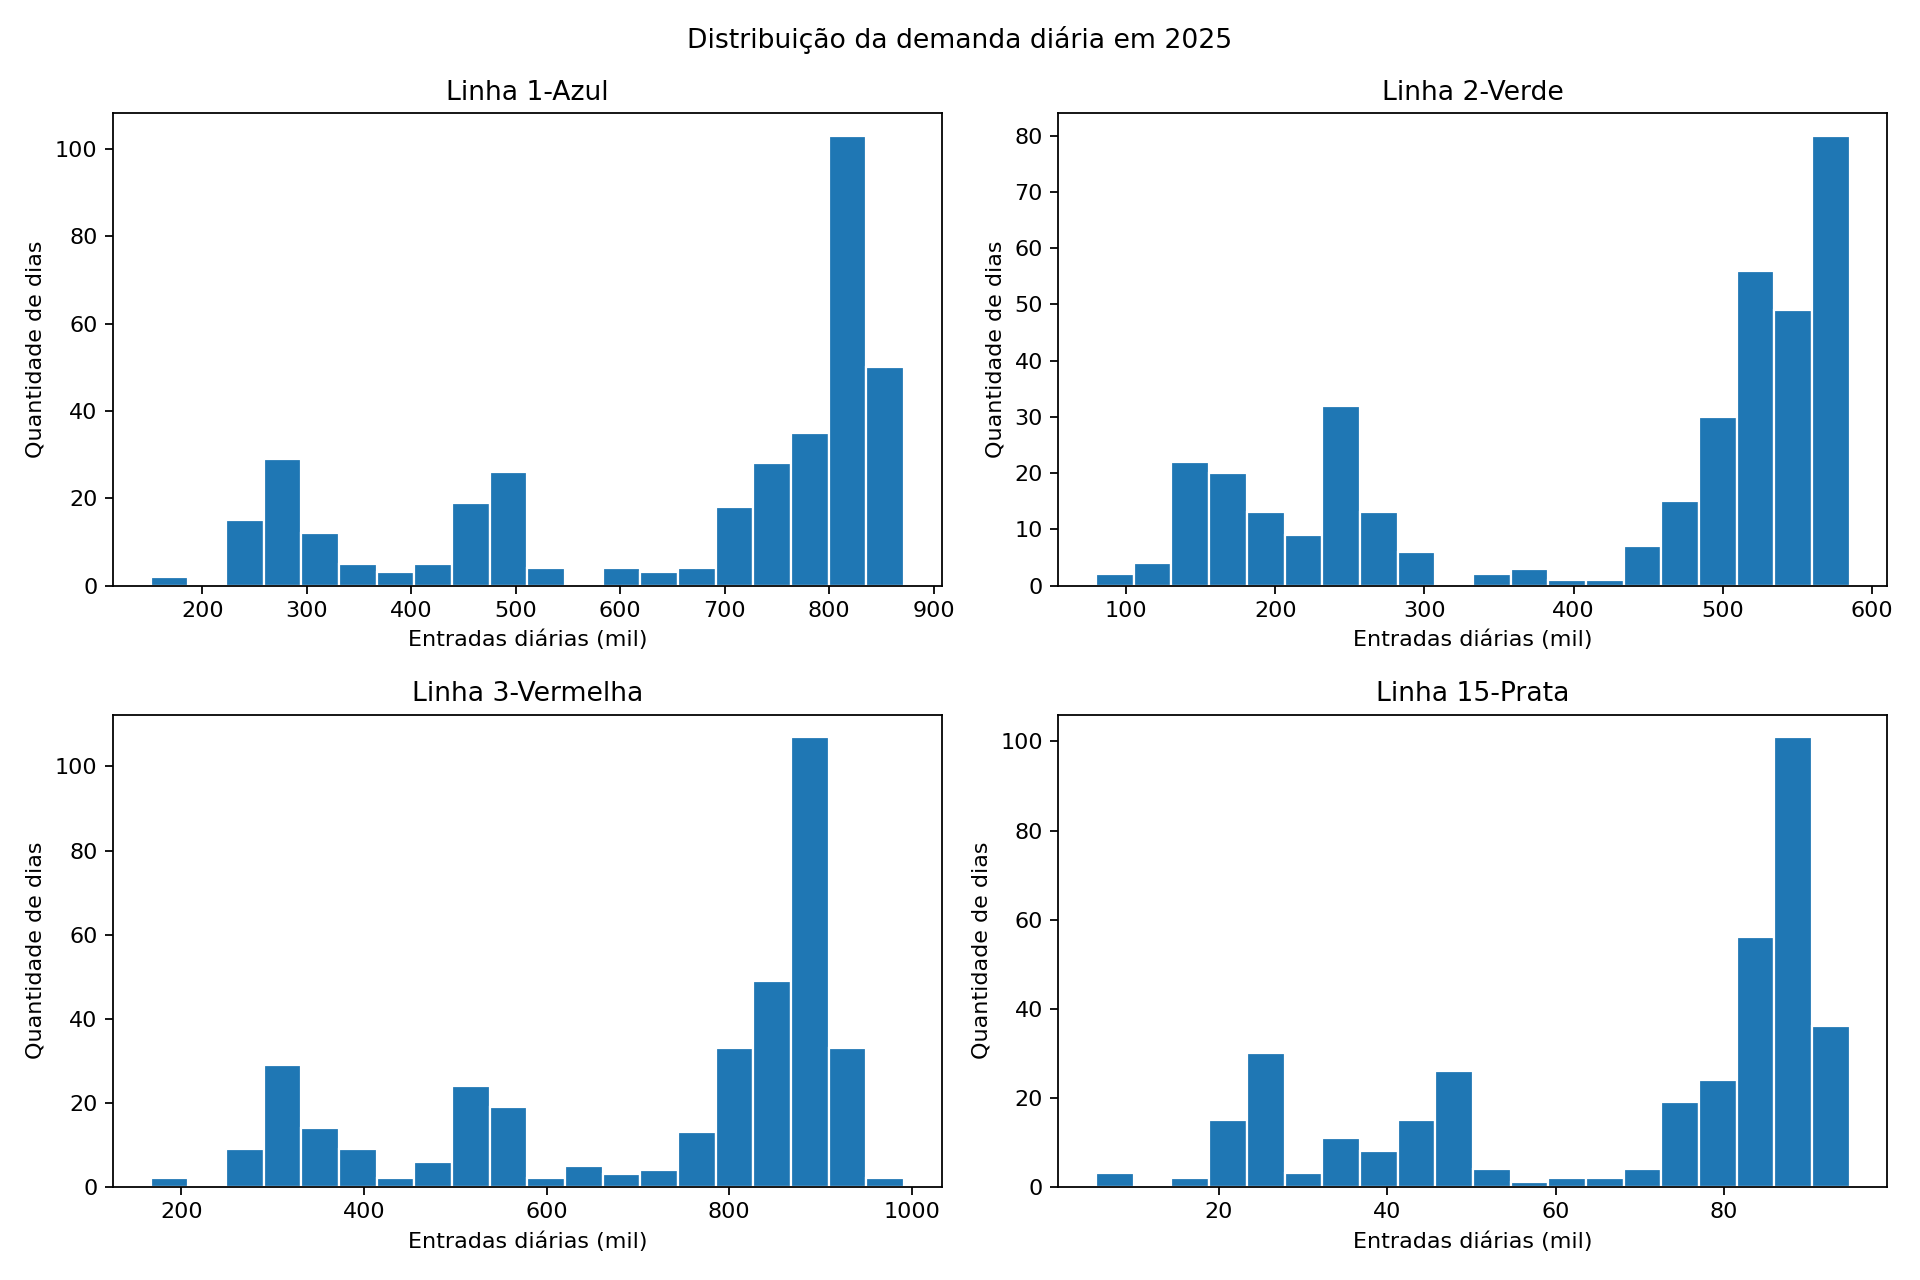

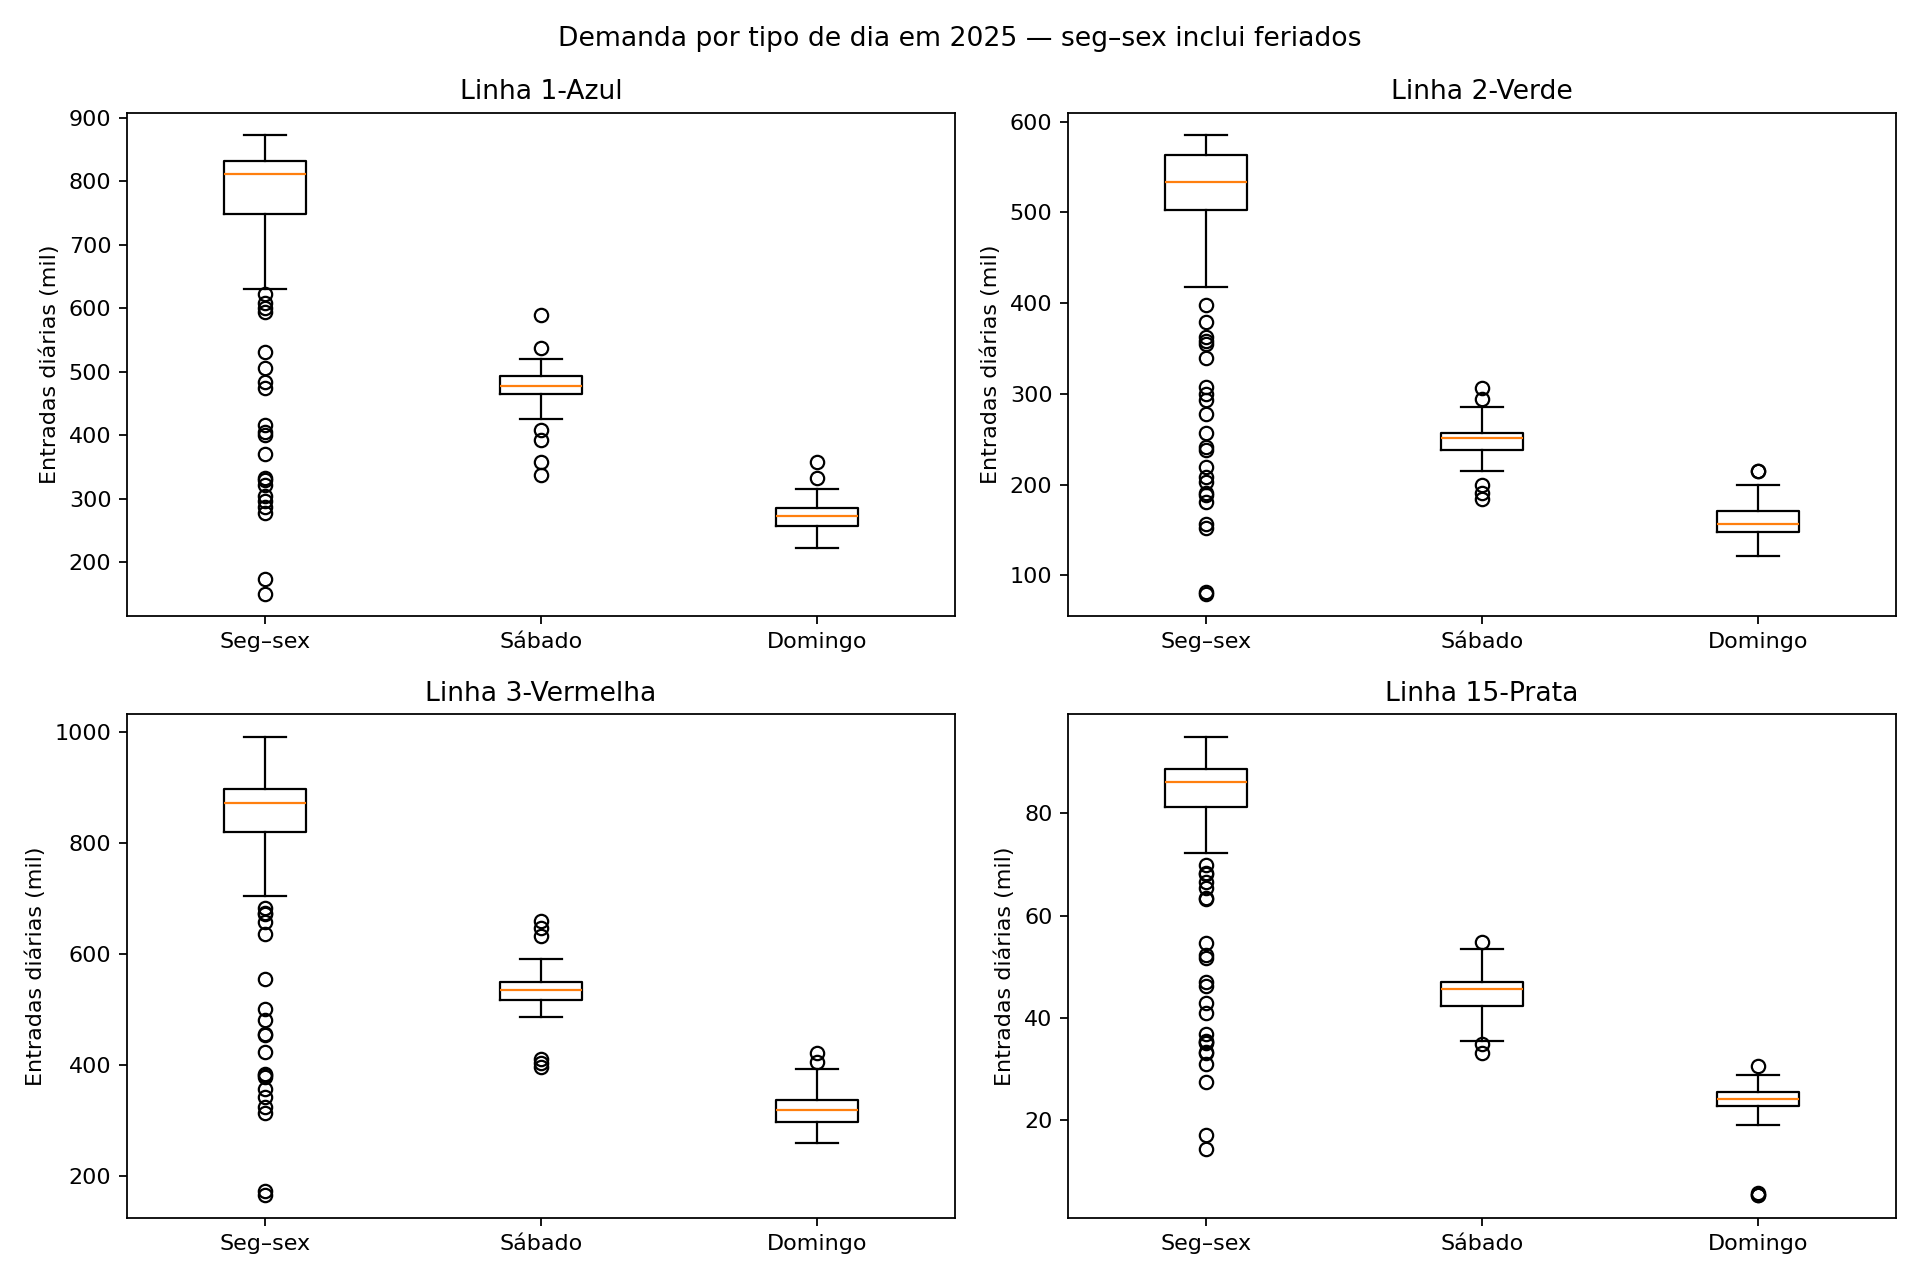

In [6]:
pontos_atipicos = pd.read_csv(resultados / "outliers_iqr.csv")
print("Sinalizações por critério e variável; uma observação pode aparecer em mais de um recorte:", len(pontos_atipicos))
display(pontos_atipicos.head(30))
display(pd.read_csv(resultados / "estatisticas_por_tipo_dia.csv"))
display(Image(filename=str(resultados / "04_histogramas_demanda.png")))
display(Image(filename=str(resultados / "05_boxplots_tipo_dia.png")))

### Leitura das distribuições
Os histogramas mostram concentrações em faixas distintas de demanda diária, compatíveis com a mistura de tipos de dia. Os boxplots evidenciam níveis mais altos de segunda a sexta, intermediários aos sábados e menores aos domingos. Os pontos fora dos limites precisam de investigação: feriados, eventos, alterações operacionais e outros fatores não foram classificados nesta base. A sinalização estatística não demonstra defeito ou efeito de manutenção.

## 6 Demanda mensal e efeito do calendário
Totais de meses com números de dias diferentes não representam diretamente a intensidade diária. O gráfico compara o total da rede publicada com esse total dividido pelos dias de calendário. A divisão não controla a composição entre dias úteis, fins de semana e feriados.

Rede publicada: maior total no mês 10; maior média por dia de calendário no mês 9.


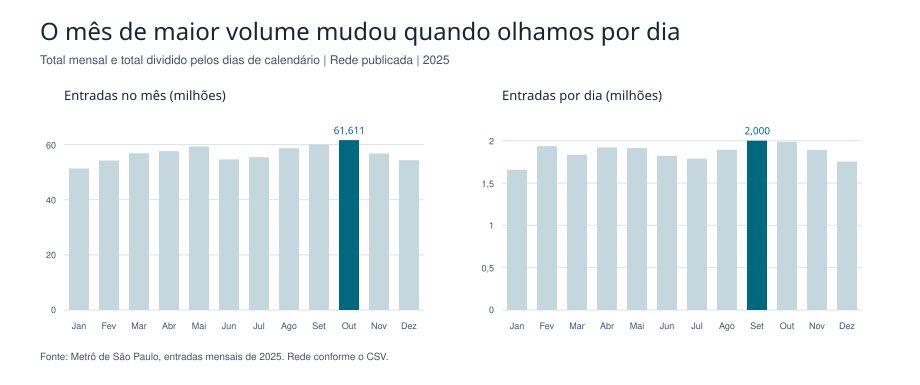

,tabela,linha,variavel,observacoes,validas,ausentes,minimo,maximo,media,mediana,variancia_amostral,desvio_padrao_amostral,q1,q3,iqr,limite_inferior,limite_superior,outliers_iqr
0,demanda_mensal,Linha 1-Azul,entradas_mil,12,12,0,18128.0,21644.0,19936.916667,19993.0,1.084424e+06,1041.356585,19207.25,20651.50,1444.25,17040.875,22817.875,0
5,demanda_mensal,Linha 15-Prata,entradas_mil,12,12,0,1862.0,2284.0,2070.250000,2062.5,1.233711e+04,111.072560,2012.75,2130.25,117.50,1836.500,2306.500,0
10,demanda_mensal,Linha 2-Verde,entradas_mil,12,12,0,11528.0,13993.0,12867.083333,12800.0,5.353314e+05,731.663417,12471.25,13392.25,921.00,11089.750,14773.750,0
15,demanda_mensal,Linha 3-Vermelha,entradas_mil,12,12,0,19816.0,23691.0,21847.166667,21842.0,1.145726e+06,1070.386067,21271.25,22598.50,1327.25,19280.375,24589.375,0
20,demanda_mensal,Rede,entradas_mil,12,12,0,51334.0,61611.0,56721.333333,56803.0,8.452233e+06,2907.272365,54542.00,58793.75,4251.75,48164.375,65171.375,0


In [7]:
display(SVG(filename=str(resultados / "01_volume_e_ritmo.svg")))
resumo_mensal = pd.read_csv(resultados / "demanda_mensal.csv")
rede = resumo_mensal.loc[resumo_mensal.linha.eq("Rede")]
pico_total = rede.loc[rede.entradas_mil.idxmax()]
pico_diario = rede.loc[rede.entradas_mil_por_dia_calendario.idxmax()]
print(f"Rede publicada: maior total no mês {int(pico_total.mes)}; maior média por dia de calendário no mês {int(pico_diario.mes)}.")
display(stats_mensais.loc[stats_mensais.variavel.eq("entradas_mil")])

## 7 Estações com maior movimentação
O ranking usa a média dos dias com valor disponível e mostra sua cobertura. Uma estação mais movimentada merece atenção na avaliação de impactos, mas a demanda não informa o estado dos seus equipamentos.

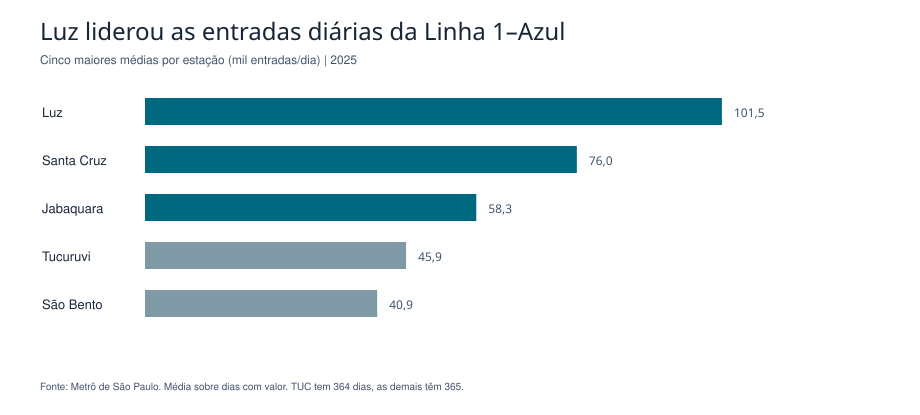

,linha,estacao,dias_base,dias_com_valor,media_entradas_mil,mediana_entradas_mil,p25_entradas_mil,cobertura_pct,total_estacao_mil,total_linha_nos_mesmos_dias_mil,participacao_entradas_pct
0,Linha 1-Azul,LUZ,365,365,101.5362,120.70,71.0,100.000,37060.7,239242.1,15.4909
1,Linha 1-Azul,SCZ,365,365,76.0030,89.10,54.7,100.000,27741.1,239242.1,11.5954
2,Linha 1-Azul,JAB,365,365,58.3047,66.20,44.8,100.000,21281.2,239242.1,8.8953
3,Linha 1-Azul,TUC,365,364,45.9492,54.65,32.3,99.726,16725.5,238884.3,7.0015
4,Linha 1-Azul,BTO,365,365,40.8638,48.80,34.9,100.000,14915.3,239242.1,6.2344
5,Linha 1-Azul,SAN,365,365,40.0315,47.40,28.0,100.000,14611.5,239242.1,6.1074
6,Linha 1-Azul,TTE,365,365,38.2975,40.30,33.6,100.000,13978.6,239242.1,5.8429
7,Linha 1-Azul,JQM,365,364,24.2863,25.45,13.3,99.726,8840.2,238833.9,3.7014
8,Linha 1-Azul,CON,365,365,23.0074,27.40,13.2,100.000,8397.7,239242.1,3.5101
9,Linha 1-Azul,LIB,365,365,22.2822,22.10,20.8,100.000,8133.0,239242.1,3.3995


In [8]:
display(SVG(filename=str(resultados / "03_concentracao_linha_azul.svg")))
ranking = pd.read_csv(resultados / "ranking_estacoes.csv")
display(ranking.loc[ranking.linha.eq("Linha 1-Azul")].head(10))

## 8 Comparação de sábados e domingos
Os totais diários são pareados no mesmo fim de semana. O código informa os pares completos em cada linha e repete o resumo usando apenas datas comuns às quatro linhas. Registros ausentes não são substituídos por zero.

52 fins de semana no calendário de 2025.
49 pares completos em comum entre as linhas.
4 tabelas em /workspace/scratch/8d74b77efb98/output/Projeto_Aplicado_I_Corrigido/resultados.
Linha 1-Azul: domingo abaixo do sábado em 52/52 pares; diferença entre médias -42.30%.
Linha 15-Prata: domingo abaixo do sábado em 49/49 pares; diferença entre médias -47.86%.
Linha 2-Verde: domingo abaixo do sábado em 52/52 pares; diferença entre médias -35.61%.
Linha 3-Vermelha: domingo abaixo do sábado em 52/52 pares; diferença entre médias -39.64%.


,linha,pares_previstos,pares_validos,sabado_media_mil,domingo_media_mil,domingo_menor_qtd,diferenca_mediana_mil,domingo_menor_pct,domingo_vs_sabado_pct,escopo
0,Linha 1-Azul,52,52,473.4038,273.1750,52,-206.85,100.0,-42.2956,pares_disponiveis_por_linha
1,Linha 15-Prata,52,49,44.3776,23.1367,49,-21.30,100.0,-47.8639,pares_disponiveis_por_linha
2,Linha 2-Verde,52,52,248.6596,160.1077,52,-89.60,100.0,-35.6117,pares_disponiveis_por_linha
3,Linha 3-Vermelha,52,52,532.9788,321.6923,52,-217.10,100.0,-39.6426,pares_disponiveis_por_linha
4,Linha 1-Azul,49,49,473.4633,272.2327,49,-208.50,100.0,-42.5018,mesmas_datas_em_todas_as_linhas
5,Linha 15-Prata,49,49,44.3776,23.1367,49,-21.30,100.0,-47.8639,mesmas_datas_em_todas_as_linhas
6,Linha 2-Verde,49,49,248.4306,158.7061,49,-89.90,100.0,-36.1165,mesmas_datas_em_todas_as_linhas
7,Linha 3-Vermelha,49,49,532.7020,321.3510,49,-217.20,100.0,-39.6753,mesmas_datas_em_todas_as_linhas


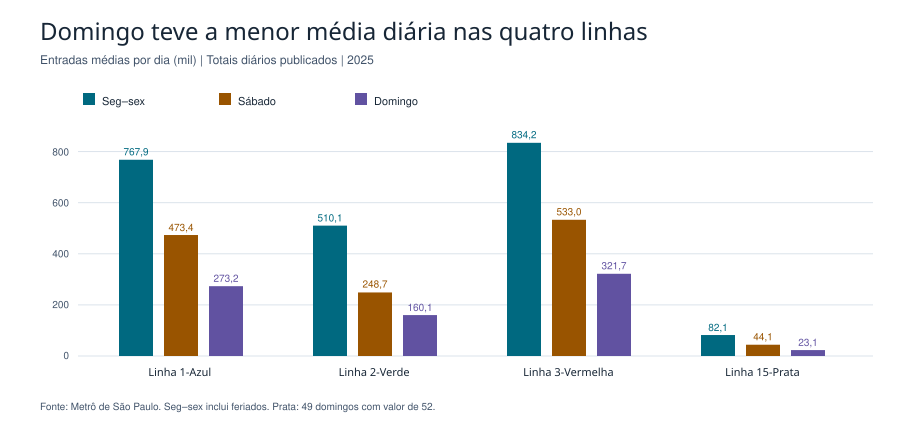

In [9]:
analise_fins_de_semana.main(["--dados", str(tratados), "--saida", str(resultados)])
resumo_fds = pd.read_csv(resultados / "resumo_por_linha.csv")
display(resumo_fds)
display(SVG(filename=str(resultados / "02_demanda_tipo_de_dia.svg")))
for registro in resumo_fds.loc[resumo_fds.escopo.eq("pares_disponiveis_por_linha")].itertuples():
    print(f"{registro.linha}: domingo abaixo do sábado em {registro.domingo_menor_qtd}/{registro.pares_validos} pares; diferença entre médias {registro.domingo_vs_sabado_pct:.2f}%.")

## 9 Oferta e infraestrutura
As medidas de oferta abrangem os meses com valor publicado. A média do intervalo mínimo mensal não representa a média de todos os intervalos reais entre trens. A infraestrutura é apresentada como contexto por característica, sem combinar unidades nem repartir a frota compartilhada.

In [10]:
display(pd.read_csv(resultados / "oferta_resumo.csv"))
display(infraestrutura.pivot(index="caracteristica", columns="linha", values="valor_fonte"))

,ano,linha,metrica,meses_base,meses_com_valor,media_valor,minimo_valor,maximo_valor
0,2026,Linha 1-Azul,intervalo_minimo_segundos,12,7,131.4286,131.0,132.0
1,2026,Linha 1-Azul,velocidade_comercial_kmh,12,7,30.0000,30.0,30.0
2,2026,Linha 15-Prata,intervalo_minimo_segundos,12,7,170.1429,170.0,171.0
3,2026,Linha 15-Prata,velocidade_comercial_kmh,12,7,35.0000,35.0,35.0
4,2026,Linha 2-Verde,intervalo_minimo_segundos,12,7,128.5714,118.0,131.0
5,2026,Linha 2-Verde,velocidade_comercial_kmh,12,7,32.0000,32.0,32.0
6,2026,Linha 3-Vermelha,intervalo_minimo_segundos,12,7,132.0000,132.0,132.0
7,2026,Linha 3-Vermelha,velocidade_comercial_kmh,12,7,32.0000,32.0,32.0


linha,Linha 1-Azul,Linha 15-Prata,Linha 2-Verde,Linha 3-Vermelha,Rede
caracteristica,,,,,
Estações com terminais de ônibus urbanos¹,7,1,4,12,22
Estações com terminais rodoviários,2,-,-,1,3
Estações de integração com a CPTM,1,-,1,4,6
Estações de integração com a Linha 4-Amarela,1,-,1,1,3
Estações de integração com a Linha 5-Lilás,1,-,1,-,2
Estações de transferência¹,3,1,3,1,4
Estações¹,23,11,14,18,63
Extensão atual das linhas (Km),"20,2","14,5","14,7",22,"71,4"
Início da Operação Comercial,1974,2015,1991,1979,-


## 10 Conclusões e limites
Os resultados descrevem diferenças entre linhas, estações, meses e tipos de dia. A comparação de pares completos mostra menor movimentação aos domingos que aos sábados nos registros analisados. Isso ajuda a investigar períodos de menor exposição de passageiros, mas não é suficiente para recomendar a execução de manutenção em todo domingo.

Ainda faltam dados de manutenção, falhas, interrupções, duração das intervenções e demanda por horário. A menor movimentação não comprova disponibilidade de equipes, equipamentos ou janelas operacionais. Os dados de demanda de 2025, oferta de 2026 e infraestrutura de 2024 não constituem uma fotografia de um único período.

Antes da entrega, atualizar o relatório e o esboço com os resultados deste notebook. Os PDFs originais foram preservados para revisão e não foram reescritos nesta correção dos códigos.